In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.linalg import expm, eigvals
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter
from itertools import product
from joblib import Parallel, delayed
import math

# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# Fig S2

In [2]:
# === Model functions ===

def A_matrix(Hvec, mu, Q):
    mat = np.full((Q, Q), mu/Q)
    np.fill_diagonal(mat, Hvec - mu*(Q-1)/Q)
    return mat

def Mcycle(Hvec, mu, Q, tau):
    matrices = []
    Hlist = [np.roll(Hvec, k) for k in range(Q)]
    for H in Hlist:
        matrices.append(expm(A_matrix(H, mu, Q)*tau - tau*np.eye(Q)))
    result = matrices[-1]
    for mat in matrices[-2::-1]:
        result = result @ mat
    return result

def rInf(Hvec, mu, Q, tau):
    mat = Mcycle(Hvec, mu, Q, tau)
    rho = max(np.real(eigvals(mat)))
    return (np.log(rho) + Q*tau) / (Q*tau)

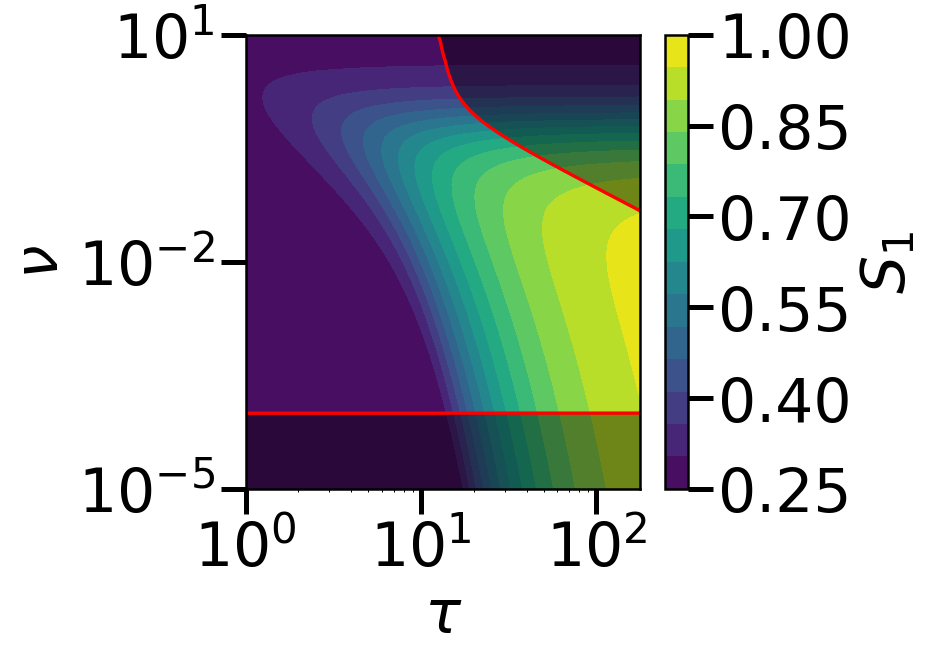

In [3]:
# ===============================
# Parameters
# ===============================

Q = 4
Hvec = np.array([1.0] + [0.0]*(Q-1))
mu_fixed = 1e-4

tau_vals = np.logspace(0, 2.25, 80)
nu_vals  = np.logspace(-5, 1, 80)

r_nu = np.zeros((len(nu_vals), len(tau_vals)))
r_mu = np.zeros_like(r_nu)

# ===============================
# Compute values
# ===============================

for j, tau in enumerate(tau_vals):
    r_mu_tau = rInf(Hvec, mu_fixed, Q, tau)
    for i, nu in enumerate(nu_vals):
        r_nu[i, j] = rInf(Hvec, nu, Q, tau)
        r_mu[i, j] = r_mu_tau   # same along ν direction

difference = r_mu - r_nu   # μ wins where > 0

# ===============================
# Plot
# ===============================

plt.figure(figsize=(8,6))

# Background: r_inf(nu)
levels = np.linspace(0.25, 1, 15)
cont = plt.contourf(tau_vals, nu_vals, r_nu,
                    levels=levels,
                    cmap="viridis")

# Phase boundary (μ = ν performance)
boundary = plt.contour(tau_vals, nu_vals, difference,
                       levels=[0],
                       colors='red',
                       linewidths=2)

# Optional: lightly shade μ-winning region
plt.contourf(tau_vals, nu_vals, difference,
             levels=[0, np.max(difference)],
             colors=['none', 'white'],
             alpha=0.4)

cbar = plt.colorbar(cont)
cbar.set_ticks(np.linspace(0.25,
                           1, 6))
cbar.set_label(r'$S_1$')
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\tau$')
plt.ylabel(r'$\nu$')

#plt.title(r'Red curve: $r_\infty(\mu)=r_\infty(\nu)$')

plt.tight_layout()
#plt.savefig('PD_tau_nu.png')
#plt.savefig('PD_tau_nu.svg')
plt.show()


# Fig S3

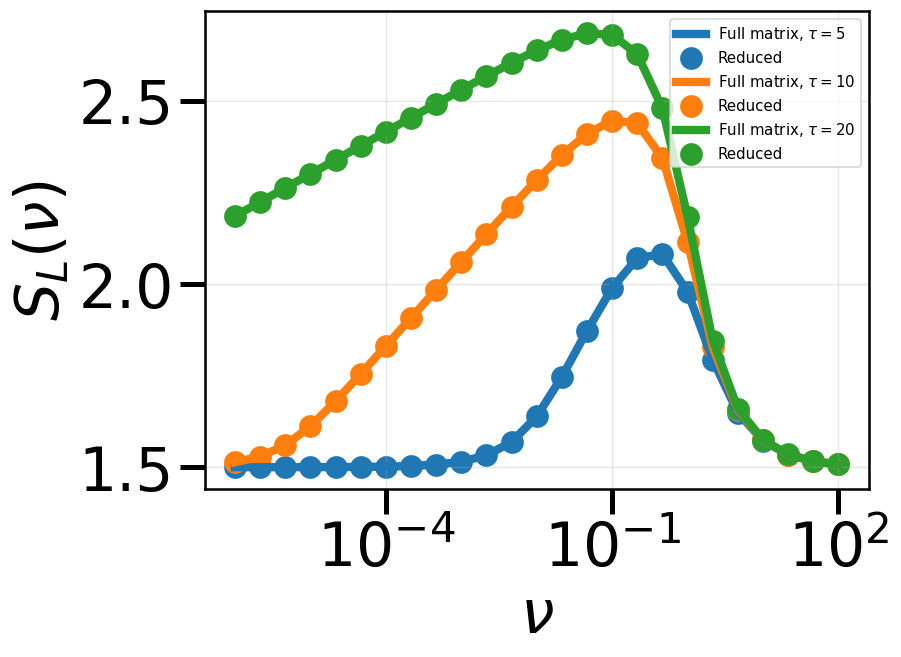

In [13]:
Q = 2
L = 3
taus = [5, 10, 20]
nu_list = np.logspace(-6, 2, 25)

# --- Exact A3 generator ---
def A3_matrix(Hvec, mu, Q):
    N = Q**3
    H3 = (Hvec[:, None, None]
        + Hvec[None, :, None]
        + Hvec[None, None, :]).reshape(N)

    A = np.full((N, N), mu / N)
    np.fill_diagonal(A, H3 - mu * (N-1)/N)
    return A

# --- Reduced exact Q=2 ---
def r_inf_exact_Q2(L, tau, nu):
    m = np.array([math.comb(L, k) for k in range(L+1)])
    A0 = (nu / 2**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()

    A0 += np.diag(np.arange(L+1) - nu)
    A1 += np.diag(L - np.arange(L+1) - nu)

    M = expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (2 * tau)

# --- Build A3 matrices (fixed structure, varying nu) ---
Hvec1 = np.array([1.0, 0.0])
Hvec2 = np.array([0.0, 1.0])

# --- Plot ---


for tau in taus:
    r_A3 = []
    r_Q2 = []

    for nu in nu_list:
        A3 = A3_matrix(Hvec1, nu, Q)
        A3_bis = A3_matrix(Hvec2, nu, Q)

        M = expm(A3 * tau) @ expm(A3_bis * tau)
        lam_max = np.max(np.real(np.linalg.eigvals(M)))
        r_A3.append(np.log(lam_max) / (2 * tau))

        r_Q2.append(r_inf_exact_Q2(L, tau, nu))

    plt.plot(nu_list, r_A3, label=rf"Full matrix, $\tau={tau}$")
    plt.scatter(nu_list, r_Q2, s=160, label=rf"Reduced")

plt.xscale("log")
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_L(\nu)$")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('Reduction.svg')
#plt.savefig('Reduction.png')
plt.show()


# Fig S4

In [3]:
def r_inf_exact_Q2(L, tau, nu):
    m = np.array([math.comb(L, k) for k in range(L+1)])
    A0 = (nu / 2**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()

    # Correct diagonal
    A0 += np.diag(np.arange(L+1) - nu )
    A1 += np.diag(L - np.arange(L+1) - nu )

    M = expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (2 * tau)

def r_inf_approx_Q2(L, tau, nu):
    return max(L/2,L-nu*(1-2**(-L))+np.log(2*nu/2**L/L)/tau)

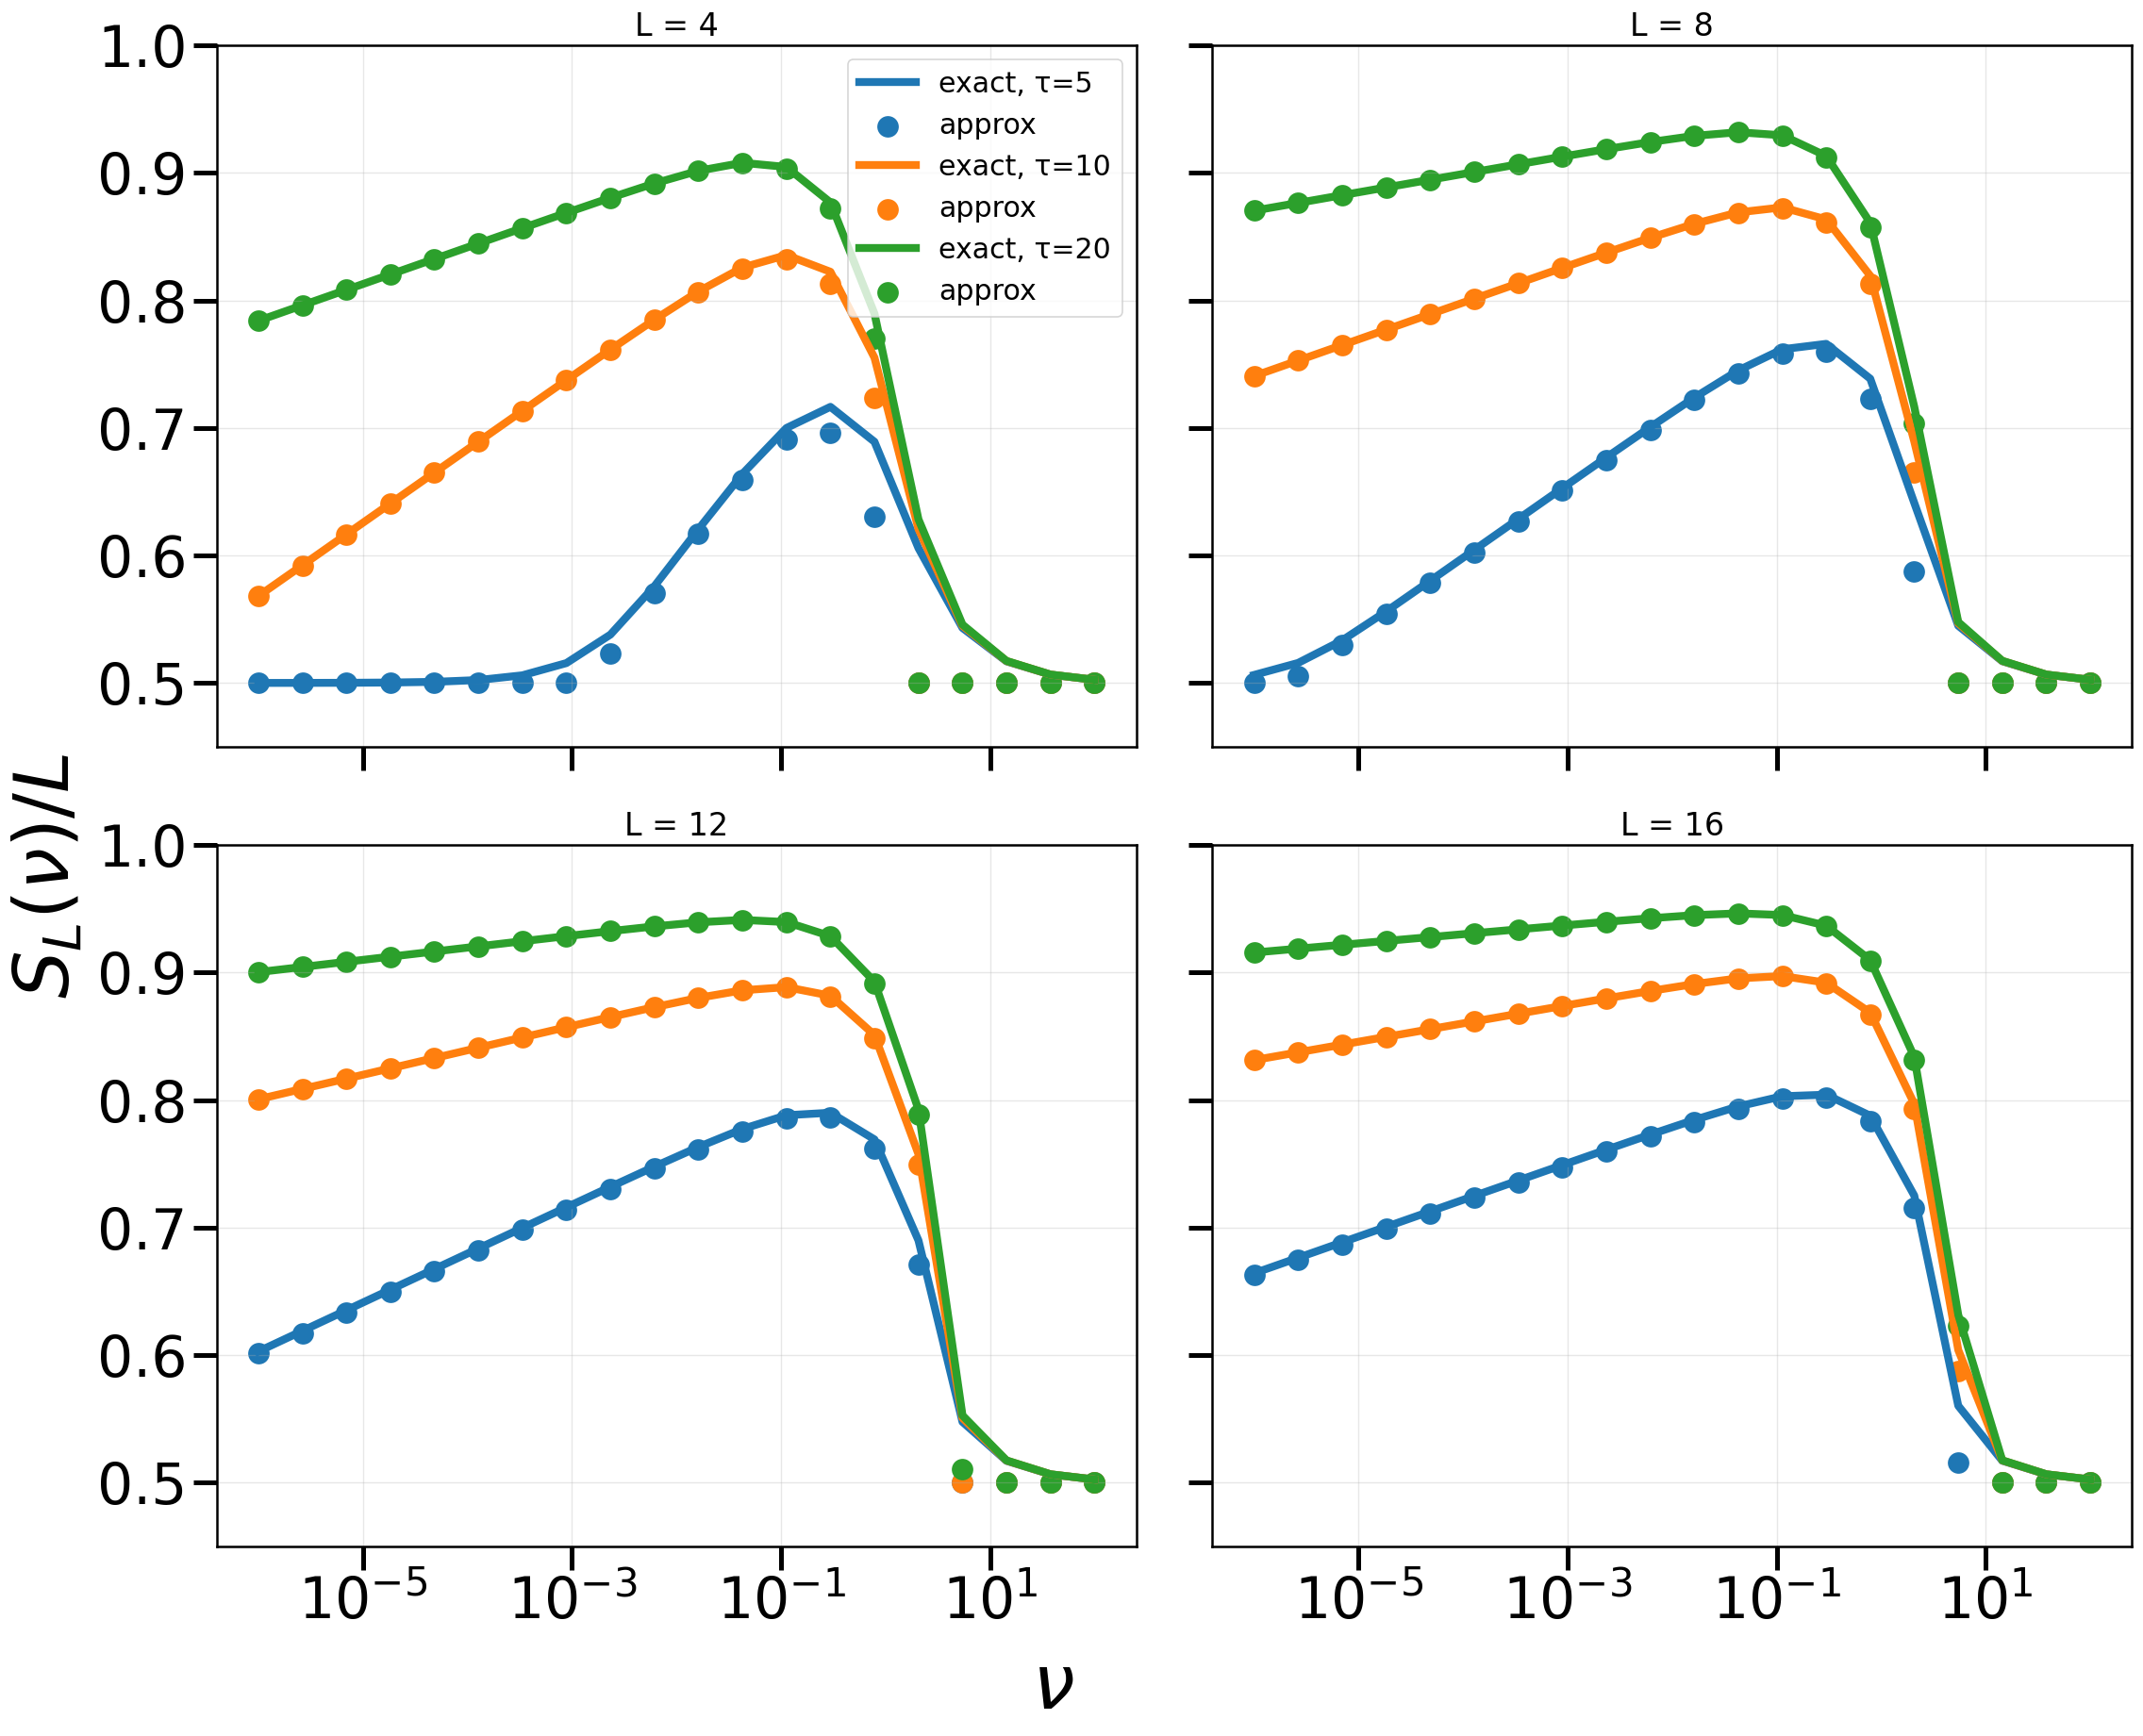

In [4]:
Ls = [4,8,12,16]
taus = [5, 10, 20]
nu_list = np.logspace(-6, 2, 20)

fig, axes = plt.subplots(2, 2, figsize=(20, 16), sharex=True, sharey=True)
axes = axes.flatten()

for ax, L in zip(axes, Ls):
    for tau in taus:
        exact = [r_inf_exact_Q2(L, tau, nu)/L for nu in nu_list]
        approx = [r_inf_approx_Q2(L, tau, nu)/L for nu in nu_list]

        ax.plot(nu_list, exact, label=f"exact, τ={tau}")
        ax.scatter(nu_list, approx, s=160, label=f"approx")

    ax.set_title(f"L = {L}")
    ax.set_xscale("log")
    ax.set_ylim(0.45, 1)
    ax.grid(True, alpha=0.3)

# Legend only in the first panel
axes[0].legend(fontsize=18)

# Common labels
fig.text(0.5, 0.04, r"$\nu$", ha="center",fontsize=48)
fig.text(0.04, 0.5, r"$S_L(\nu) / L$", va="center", rotation="vertical",fontsize=48)

plt.tight_layout(rect=[0.06, 0.06, 1, 1])
plt.savefig('S_L.svg')
#plt.savefig('S_L.png')
plt.show()


# Fig S5

[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 1, 0), (1, 1, 1), (1, 2, 0), (2, 0, 0), (2, 0, 1), (2, 1, 0), (3, 0, 0)]
[(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 2, 0), (0, 2, 1), (0, 3, 0), (1, 0

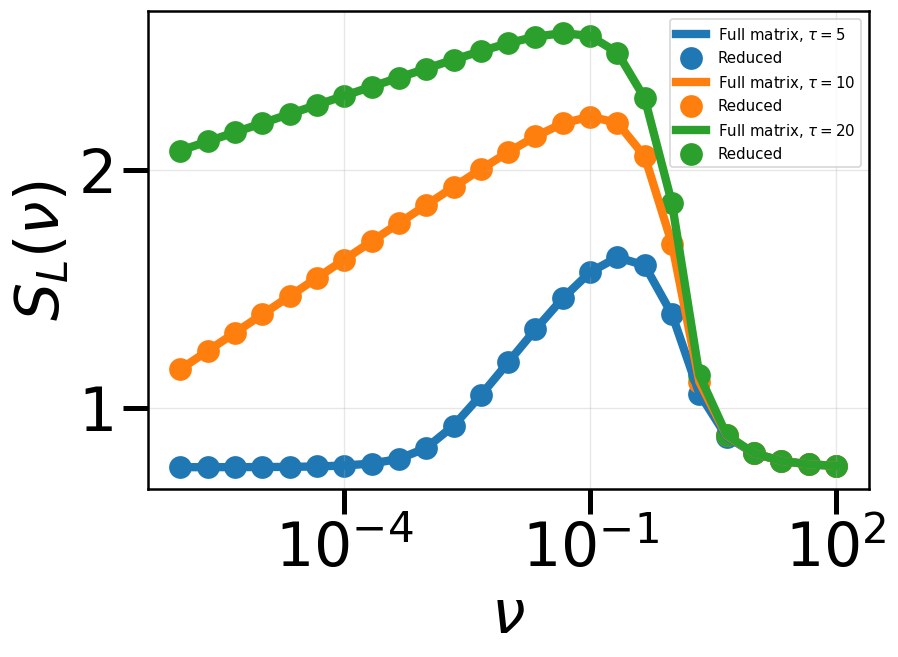

In [7]:
Q = 4
L = 3
taus = [5, 10, 20]
nu_list = np.logspace(-6, 2, 25)

# --- Exact A3 generator ---
def A3_matrix(Hvec, mu, Q):
    N = Q**L
    H3 = (Hvec[:, None, None]
        + Hvec[None, :, None]
        + Hvec[None, None, :]).reshape(N)

    A = np.full((N, N), mu / N)
    np.fill_diagonal(A, H3 - mu * (N-1)/N)
    return A

# --- Reduced exact Q=4 ---
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()

    A0 += np.diag([k0 - nu for (k0,k1,k2) in Ks])
    A1 += np.diag([k1 - nu for (k0,k1,k2) in Ks])
    A2 += np.diag([k2 - nu for (k0,k1,k2) in Ks])
    A3 += np.diag([L-k1-k2-k3 - nu for (k1,k2,k3) in Ks])
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (4 * tau)

# --- Build A3 matrices (fixed structure, varying nu) ---
Hvec1 = np.array([1.0, 0.0,0.0,0.0])
Hvec2 = np.array([0.0, 1.0,0.0,0.0])
Hvec3 = np.array([0.0, 0.0,1.0,0.0])
Hvec4 = np.array([0.0, 0.0,0.0,1.0])
# --- Plot ---


for tau in taus:
    r_A3 = []
    r_Q4 = []

    for nu in nu_list:
        A3 = A3_matrix(Hvec1, nu, Q)
        A3_bis = A3_matrix(Hvec2, nu, Q)
        A3_ter = A3_matrix(Hvec3, nu, Q)
        A3_qua = A3_matrix(Hvec4, nu, Q)
        M = expm(A3 * tau) @ expm(A3_bis * tau)@ expm(A3_ter * tau)@ expm(A3_qua * tau)
        lam_max = np.max(np.real(np.linalg.eigvals(M)))
        r_A3.append(max(np.log(lam_max) / (4 * tau),L/4))

        r_Q4.append(max(r_inf_exact_Q4(L, tau, nu),L/4))

    plt.plot(nu_list, r_A3, label=rf"Full matrix, $\tau={tau}$")
    plt.scatter(nu_list, r_Q4, s=160, label=rf"Reduced")

plt.xscale("log")
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_L(\nu)$")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('Reduction_Q4.png')
#plt.savefig('Reduction_Q4.svg')
plt.show()

# Fig S6

In [5]:
Q=4
# --- Reduced exact Q=4 ---
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()
    A0 += np.diag([k0 - nu for (k0,k1,k2) in Ks])
    A1 += np.diag([k1 - nu for (k0,k1,k2) in Ks])
    A2 += np.diag([k2 - nu for (k0,k1,k2) in Ks])
    A3 += np.diag([L-k1-k2-k3 - nu for (k1,k2,k3) in Ks])
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (4 * tau)

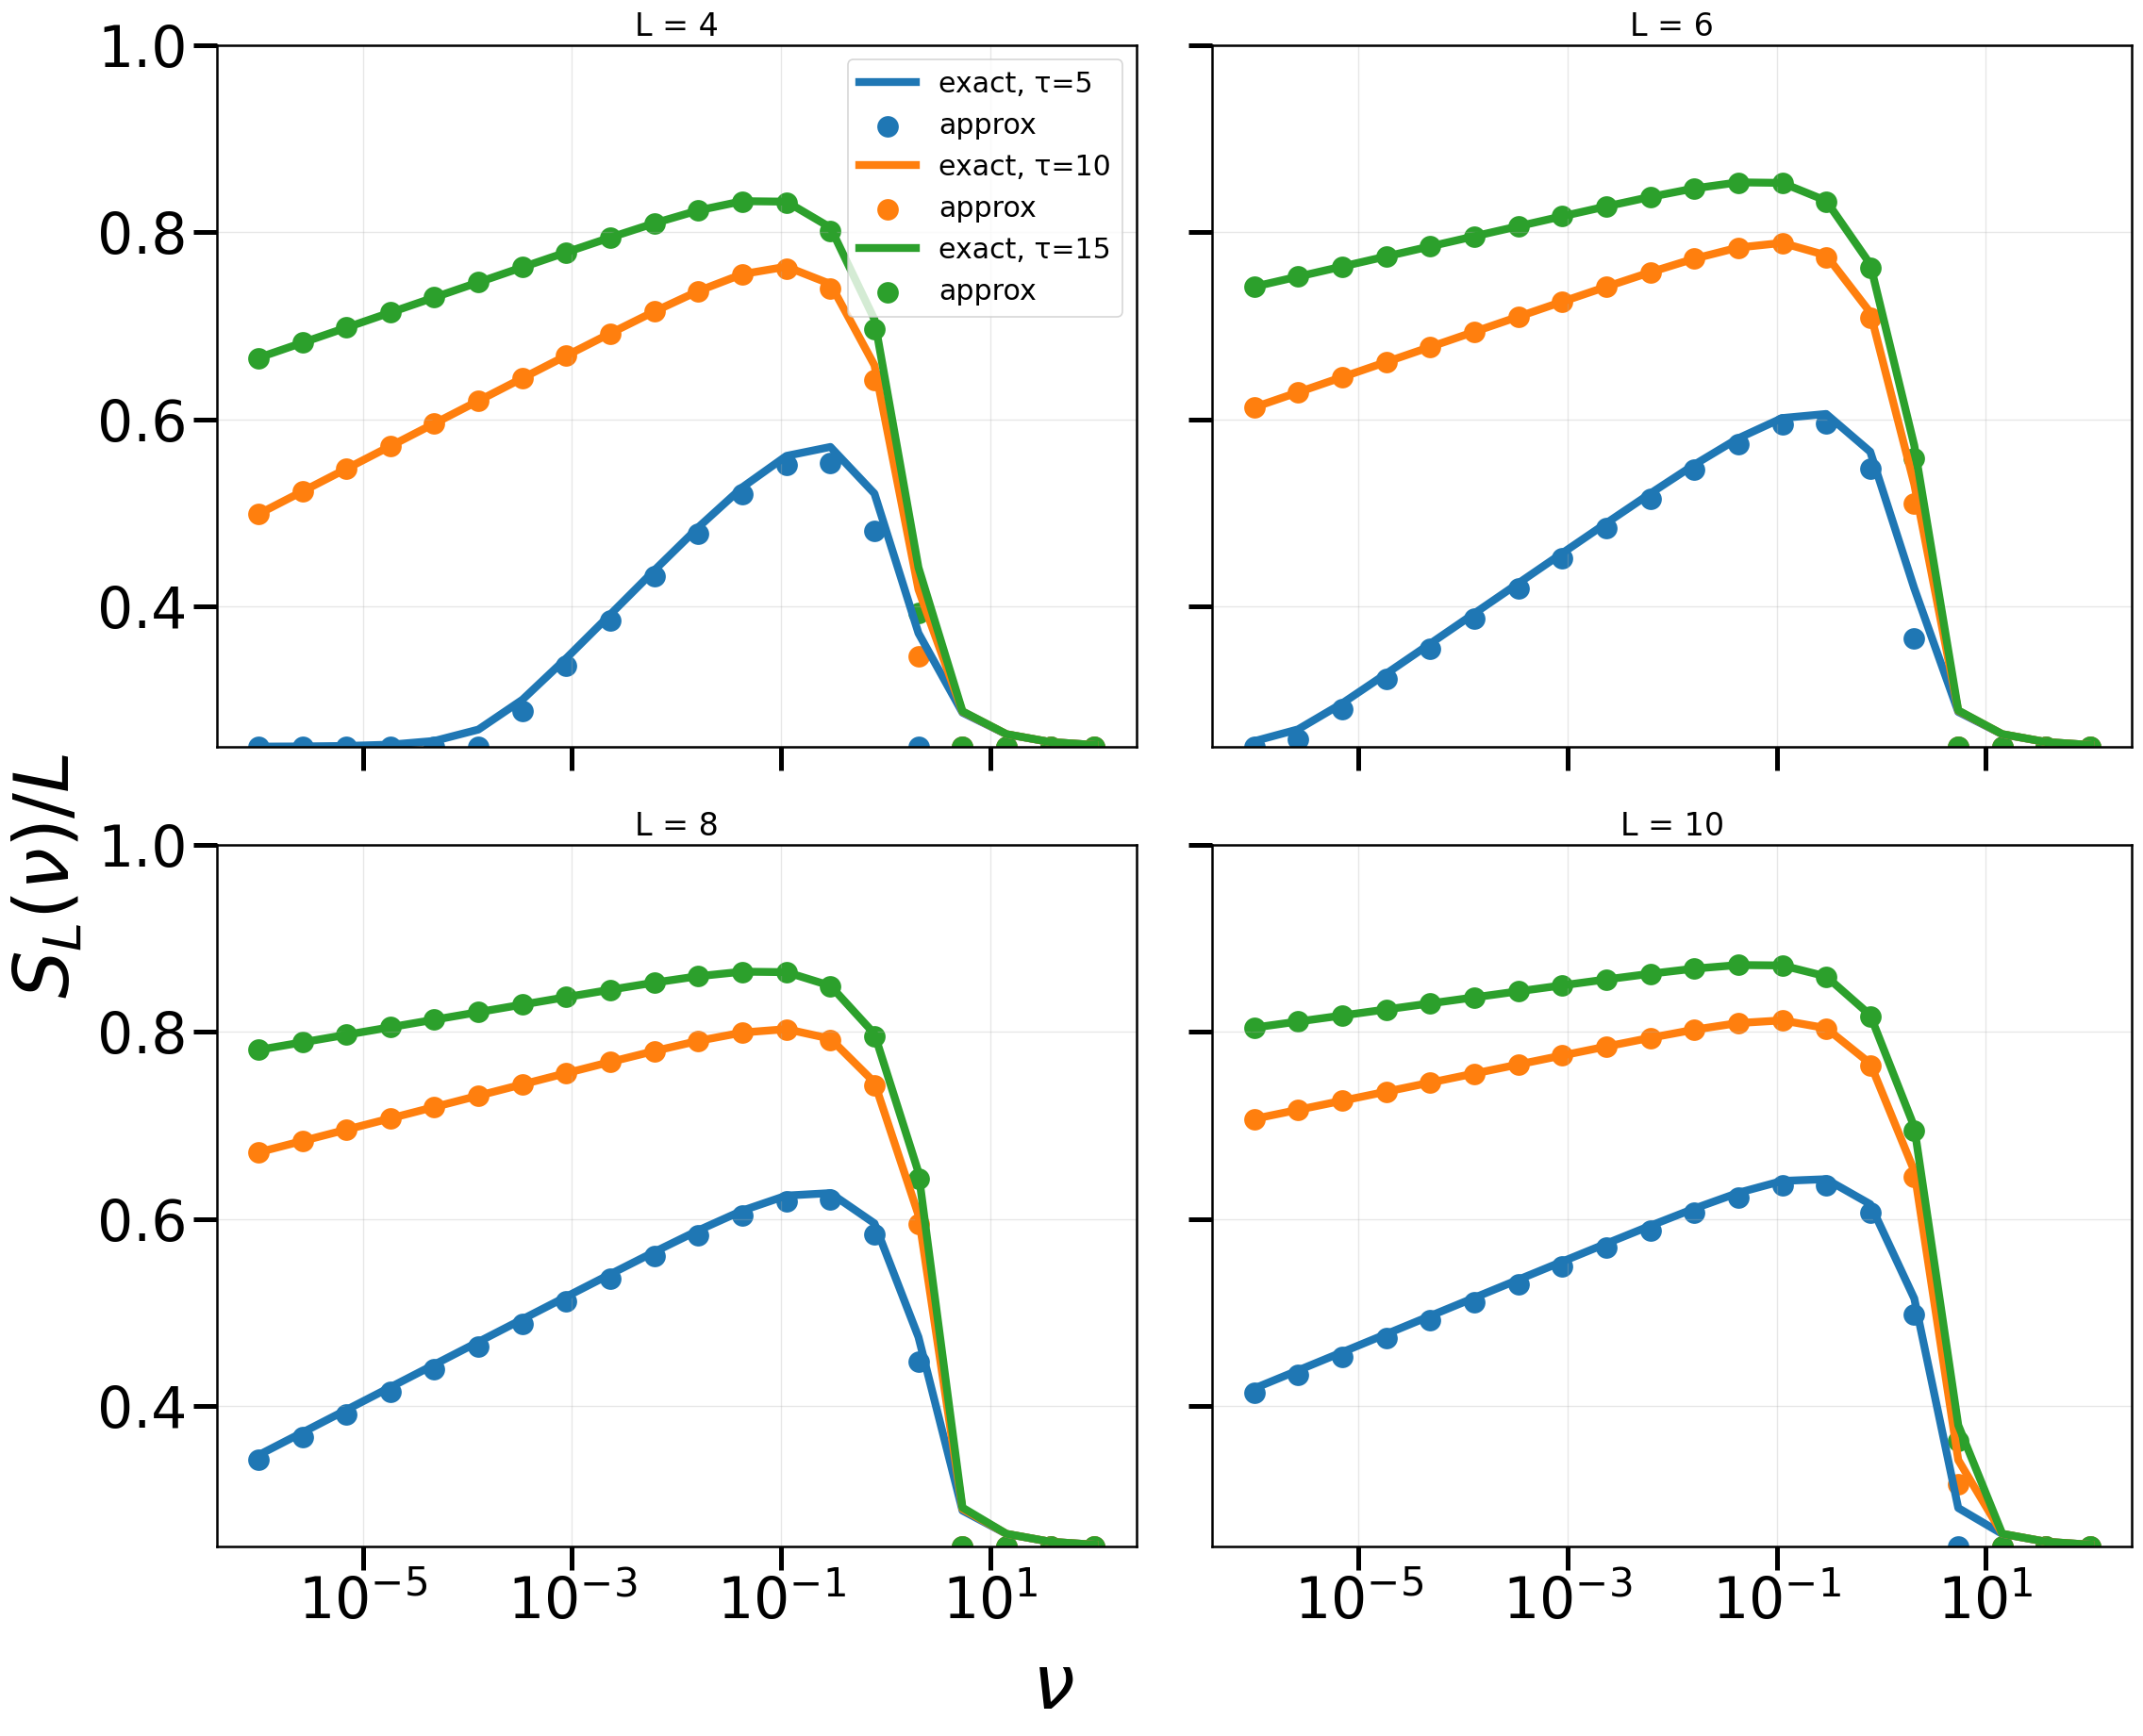

In [6]:
Ls = [4,6,8,10]
taus = [5, 10, 15]
nu_list = np.logspace(-6, 2, 20)

fig, axes = plt.subplots(2, 2, figsize=(20, 16), sharex=True, sharey=True)
axes = axes.flatten()

for ax, L in zip(axes, Ls):
    for tau in taus:
        exact = [r_inf_exact_Q4(L, tau, nu)/L for nu in nu_list]
        approx = [max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau)/L for nu in nu_list]

        ax.plot(nu_list, exact, label=f"exact, τ={tau}")
        ax.scatter(nu_list, approx, s=160, label=f"approx")

    ax.set_title(f"L = {L}")
    ax.set_xscale("log")
    ax.set_ylim(1/Q, 1)
    ax.grid(True, alpha=0.3)

# Legend only in the first panel
axes[0].legend(fontsize=18)

# Common labels
fig.text(0.5, 0.04, r"$\nu$", ha="center",fontsize=48)
fig.text(0.04, 0.5, r"$S_L(\nu) / L$", va="center", rotation="vertical",fontsize=48)

plt.tight_layout(rect=[0.06, 0.06, 1, 1])
#plt.savefig('S_L_Q4.png')
plt.savefig('S_L_Q4.svg')
plt.show()


# Fig S7

In [10]:
def r_inf_exact_Q4(L, tau, nu):
    Ks= [(k1, k2, k3) for k1, k2, k3 in product(range(L+1), repeat=3) if k1 + k2 + k3 <= L]
    print(len(Ks))
    m = np.array([(
    math.comb(L, k1)
    * math.comb(L - k1, k2)
    * math.comb(L - k1 - k2, k3)
) for (k1,k2,k3) in Ks])
    A0 = (nu / Q**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()
    A2=A0.copy()
    A3=A0.copy()
    A0 += np.diag([k0 - nu for (k0,k1,k2) in Ks])-np.eye(len(Ks))*L
    A1 += np.diag([k1 - nu for (k0,k1,k2) in Ks])-np.eye(len(Ks))*L
    A2 += np.diag([k2 - nu for (k0,k1,k2) in Ks])-np.eye(len(Ks))*L
    A3 += np.diag([L-k1-k2-k3 - nu for (k1,k2,k3) in Ks])-L*np.eye(len(Ks))
    M = expm(A3 * tau) @expm(A2 * tau) @expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return max((np.log(lam_max)+4*tau*L) / (4 * tau),L/4)


def compute_r_value(L, Q, tau, nu):
    val = r_inf_exact_Q4(L, tau, nu)

    if np.isnan(val):
        approx = max(
            L / Q,
            L - nu * (1 - Q**(-L)) + np.log(2*nu / Q**L / L) / tau
        )
        return approx
    return val

/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.py:19: RuntimeWarning: divide by zero encountered in log
/tmp/ipykernel_8773/3969357851.p

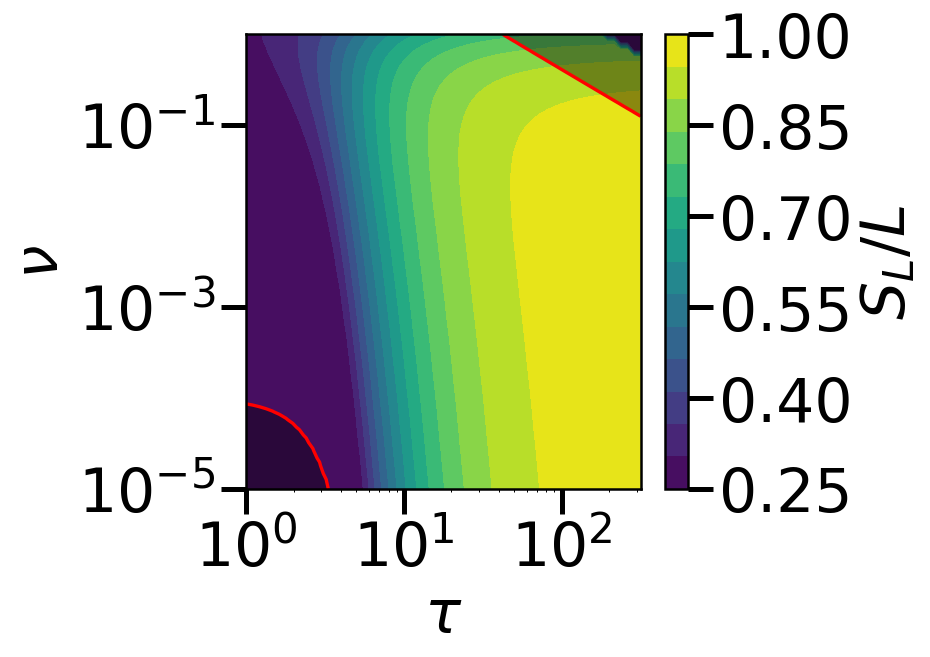

In [11]:
# ===============================
# Parameters
# ===============================

Q = 4
Hvec = np.array([1.0] + [0.0]*(Q-1))
mu_fixed = 1e-4

tau_vals = np.logspace(0, 2.5, 60)
nu_vals  = np.logspace(-5, 0, 60)

r_nu = np.zeros((len(nu_vals), len(tau_vals)))
r_mu = np.zeros_like(r_nu)

# ===============================
# Compute values
# ===============================

L=5

for j, tau in enumerate(tau_vals):

    r_mu_tau = rInf(Hvec, mu_fixed, Q, tau)

    r_nu_col = Parallel(n_jobs=-1)(
        delayed(compute_r_value)(L, Q, tau, nu)
        for nu in nu_vals
    )

    r_nu[:, j] = np.array(r_nu_col) / L
    r_mu[:, j] = r_mu_tau

difference = r_mu - r_nu   # μ wins where > 0

# ===============================
# Plot
# ===============================

plt.figure(figsize=(8,6))

# Background: r_inf(nu)
levels = np.linspace(0.25, 1, 15)
cont = plt.contourf(tau_vals, nu_vals, r_nu,
                    levels=levels,
                    cmap="viridis")

# Phase boundary (μ = ν performance)
boundary = plt.contour(tau_vals, nu_vals, difference,
                       levels=[0],
                       colors='red',
                       linewidths=2)

# Optional: lightly shade μ-winning region
plt.contourf(tau_vals, nu_vals, difference,
             levels=[0, np.max(difference)],
             colors=['none', 'white'],
             alpha=0.4)

cbar = plt.colorbar(cont)
cbar.set_ticks(np.linspace(0.25,
                           1, 6))
cbar.set_label(r'$S_L/L$')
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\tau$')
plt.ylabel(r'$\nu$')

#plt.title(r'Red curve: $r_\infty(\mu)=r_\infty(\nu)$')

plt.tight_layout()
#plt.savefig('PD_tau_nu_L.svg')
#plt.savefig('PD_tau_nu_L.png')
plt.show()